<a href="https://colab.research.google.com/github/20deepak28/Customer-Lifetime-Value-Churn-Intelligence/blob/main/03_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

In [5]:
project_path = '/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence'

data_path = os.path.join(project_path, 'data')

In [6]:
file_path = os.path.join(data_path, 'telco_churn_processed.csv')

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
print("Columns:", df.columns.tolist())

print("\nMissing Values:", df.isnull().sum().sum())

print("\nData Types:")
df.info()

Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing Values: 0

Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   Online

### Create ML Dataset

In [8]:
ml_df = df.copy()

print("Dataset Shape:", ml_df.shape)
ml_df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
ml_df.drop(columns=['customerID'], inplace=True)

print(ml_df.shape)

(7043, 20)


### Create Customer Tenure Groups

In [10]:
ml_df['TenureGroup'] = pd.cut(
    ml_df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        'New',
        'Developing',
        'Established',
        'Loyal'
    ]
)

In [11]:
print(ml_df['TenureGroup'].value_counts().sort_index())

TenureGroup
New            2186
Developing     1024
Established    1594
Loyal          2239
Name: count, dtype: int64


### Create Additional Service Count

In [12]:
service_columns = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

ml_df['AdditionalServicesCount'] = (
    ml_df[service_columns] == 'Yes'
).sum(axis=1)

In [13]:
ml_df['AdditionalServicesCount'].value_counts().sort_index()

,count
AdditionalServicesCount,
0,2219
1,966
2,1033
3,1118
4,852
5,571
6,284


### Analyze our new features

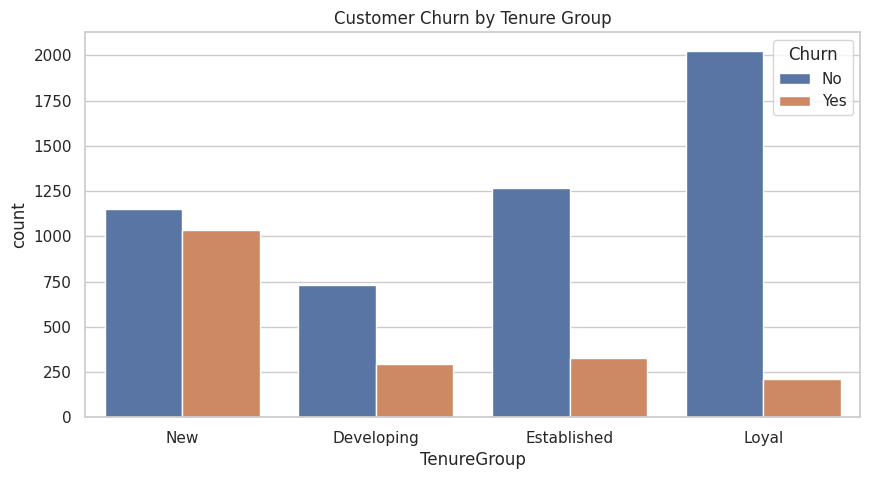

In [14]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=ml_df,
    x='TenureGroup',
    hue='Churn'
)

plt.title('Customer Churn by Tenure Group')
plt.show()

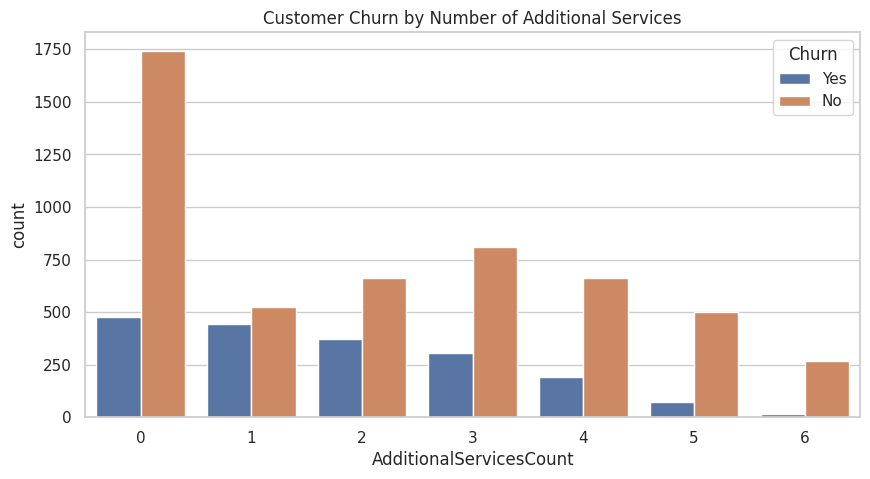

In [15]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=ml_df,
    x='AdditionalServicesCount',
    hue='Churn'
)

plt.title('Customer Churn by Number of Additional Services')
plt.show()

In [16]:
print(
    pd.crosstab(
        ml_df['AdditionalServicesCount'],
        ml_df['Churn'],
        normalize='index'
    ).round(3) * 100
)

Churn                      No   Yes
AdditionalServicesCount            
0                        78.6  21.4
1                        54.2  45.8
2                        64.2  35.8
3                        72.6  27.4
4                        77.7  22.3
5                        87.6  12.4
6                        94.7   5.3


### final Dataset Inspection

In [17]:
display(ml_df.head(10))

print("\nDataset Shape:", ml_df.shape)

print("\nMissing Values:")
print(ml_df.isnull().sum().sum())

print("\nData Types:")
print(ml_df.dtypes)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,AdditionalServicesCount
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,No,Established,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,New,2
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Established,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,New,0
5,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,New,3
6,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,...,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No,Developing,2
7,Female,0,No,No,10,No,No phone service,DSL,Yes,No,...,No,No,Month-to-month,No,Mailed check,29.75,301.90,No,New,1
8,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,Established,4
9,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,...,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No,Loyal,2



Dataset Shape: (7043, 22)

Missing Values:
0

Data Types:
gender                       object
SeniorCitizen                 int64
Partner                      object
Dependents                   object
tenure                        int64
PhoneService                 object
MultipleLines                object
InternetService              object
OnlineSecurity               object
OnlineBackup                 object
DeviceProtection             object
TechSupport                  object
StreamingTV                  object
StreamingMovies              object
Contract                     object
PaperlessBilling             object
PaymentMethod                object
MonthlyCharges              float64
TotalCharges                float64
Churn                        object
TenureGroup                category
AdditionalServicesCount       int64
dtype: object


In [18]:
feature_path = os.path.join(
    data_path,
    'telco_churn_feature_engineered.csv'
)

ml_df.to_csv(feature_path, index=False)

print("Feature-engineered dataset saved!")

Feature-engineered dataset saved!


### Calculate Churn Rate

In [19]:
churn_by_services = ml_df.groupby(
    'AdditionalServicesCount',
    observed=True
)['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(churn_by_services)

AdditionalServicesCount
0    21.406039
1    45.755694
2    35.818006
3    27.370304
4    22.300469
5    12.434326
6     5.281690
Name: Churn, dtype: float64


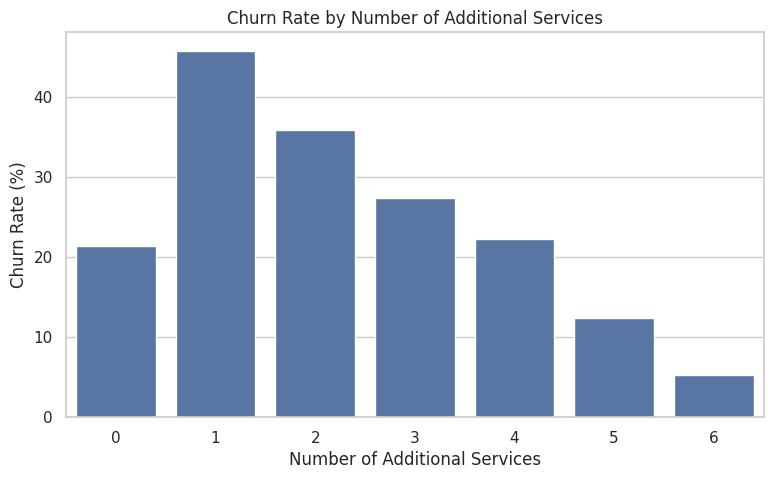

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=churn_by_services.index,
    y=churn_by_services.values
)

plt.title('Churn Rate by Number of Additional Services')
plt.xlabel('Number of Additional Services')
plt.ylabel('Churn Rate (%)')

plt.show()

### Buisness interpretation

In [21]:
ml_df['AdditionalServicesCount'].value_counts().sort_index()

,count
AdditionalServicesCount,
0,2219
1,966
2,1033
3,1118
4,852
5,571
6,284


### Additional Services vs Customer Churn

- Customers with more additional services generally demonstrate lower churn rates.
- Customers with exactly one additional service show the highest churn rate.
- Customers subscribing to all six additional services show the lowest churn rate.
- The largest customer segment has zero additional services (2,219 customers).
- This relationship indicates a useful predictive feature for churn modelling.

Business Insight:
Customers with limited service adoption may represent an opportunity for
targeted cross-selling and customer engagement strategies.

Note: These findings represent associations, not causal relationships.

### Tenure Group vs churn

In [23]:
pd.crosstab(
    ml_df['TenureGroup'],
    ml_df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
TenureGroup,,
New,52.561757,47.438243
Developing,71.289062,28.710938
Established,79.611041,20.388959
Loyal,90.486824,9.513176


### Tenure Group vs Customer Churn

The analysis reveals a strong negative relationship between customer tenure and churn.

| Tenure Group | Churn Rate |
|---|---:|
| New | 47.44% |
| Developing | 28.71% |
| Established | 20.39% |
| Loyal | 9.51% |

**Business Insight:** New customers represent the highest-risk segment, with approximately 47.44% churn. Retention strategies should prioritise the first 12 months of the customer lifecycle.

**Conclusion:** TenureGroup is a potentially useful engineered feature for the churn prediction model.

### Feature engineering validation

In [24]:
print("Missing values:")
print(ml_df[['TenureGroup', 'AdditionalServicesCount']].isnull().sum())

print("\nDataset shape:")
print(ml_df.shape)

print("\nDuplicate rows:")
print(ml_df.duplicated().sum())

Missing values:
TenureGroup                0
AdditionalServicesCount    0
dtype: int64

Dataset shape:
(7043, 22)

Duplicate rows:
22


### Checking og data

In [25]:
print("Original dataset duplicates:", df.duplicated().sum())

print("Duplicate customer IDs:", df['customerID'].duplicated().sum())

Original dataset duplicates: 0
Duplicate customer IDs: 0


### Inspect the duplicate in ml_df

In [26]:
duplicates = ml_df[ml_df.duplicated(keep=False)]

duplicates.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,AdditionalServicesCount
22,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes,New,0
100,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.20,No,New,0
542,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No,New,0
646,Male,0,No,No,1,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes,New,0
662,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No,New,0
690,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,No,New,0
964,Male,0,No,No,1,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes,New,0
976,Male,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,Yes,New,0
1243,Male,0,No,No,1,Yes,No,DSL,No,No,...,No,No,Month-to-month,No,Electronic check,45.30,45.30,Yes,New,0
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes,New,0


Save the final feature-engineered dataset

In [27]:
feature_path = os.path.join(
    data_path,
    'telco_churn_feature_engineered.csv'
)

ml_df.to_csv(feature_path, index=False)

print("Final feature-engineered dataset saved!")
print("Shape:", ml_df.shape)

Final feature-engineered dataset saved!
Shape: (7043, 22)
